In [1]:
import numpy as np

import matplotlib.pyplot as plt

# Changing the number of dimensions d

In [18]:
path = "../results/grad_accuracy/changing_d"
dims = [1, 2, 3, 5, 6, 7, 10, 20, 50, 100]
methods = ['FFD_G', 'FFD_SP', 'FFD_CO', 'FFD_QR', 'CFD_G', 'CFD_SP', 'CFD_CO', 'CFD_QR', 'GGA_G', 'GGA_SP', 'GGA_CO', 'GGA_QR', 'CGGA_G', 'CGGA_SP', 'CGGA_CO', 'CGGA_QR', 'LI_G', 'LI_SP', 'LI_CO', 'LI_QR', 'CLI_G', 'CLI_SP', 'CLI_CO', 'CLI_QR', 'GSGA_CO', 'CGSGA_CO', 'GSGA_QR', 'CGSGA_QR']


In [69]:
fun = "Sphere"
results = {}
c = 0
# Load results
for d in dims:
    results[d] = {}
    with open(f"{path}/{fun}_{d}_{d}.log", 'r') as f:
        lines = f.readlines()
        for line in lines:
            if '[++]' in line:
                results[d][c] = {}
                c += 1
            else:
                spl = line.strip().split(",")
                results[d][c - 1][spl[0]] = (float(spl[1]), float(spl[2]))
        c= 0
                                

In [72]:
def plot_result(title, res, out):
    fig, ax = plt.subplots()
    ax.set_title(title, fontsize=20)
    means = []
    stds = []
    labels= []
    for (k, v) in res.items():
        if 'CLI' in k:
            continue
        means.append(v[0] + 1e-20)
        stds.append(v[1])
        labels.append(k.replace("_",'-'))
    means = np.asarray(means)
    stds = np.asarray(stds)
    ax.errorbar([i + 5 for i in range(len(means))], means, fmt='o', c='red', yerr=stds)
    ax.set_xticks([i + 5 for i in range(len(means))], labels, rotation='vertical')
    ax.set_yscale("log")
    ax.set_ylabel("$\\frac{\\| \\nabla f(x) - g(x) \\|}{\\| \\nabla f(x) \\|}$", fontsize=18)
    fig.savefig(f"{path}/{out}", bbox_inches='tight')
    

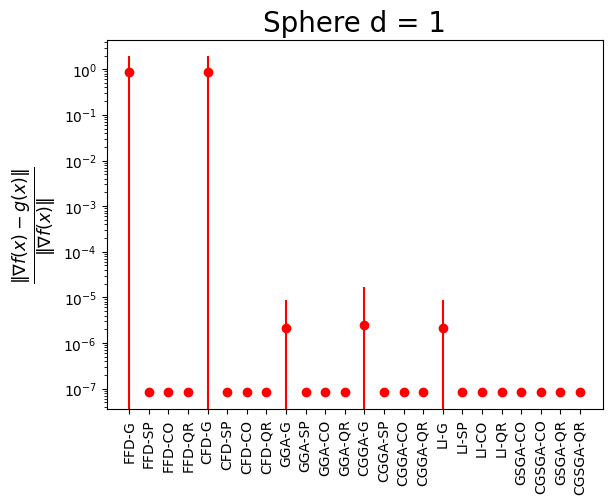

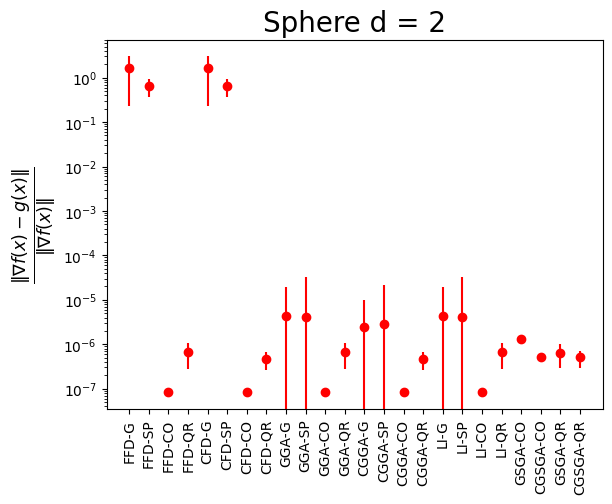

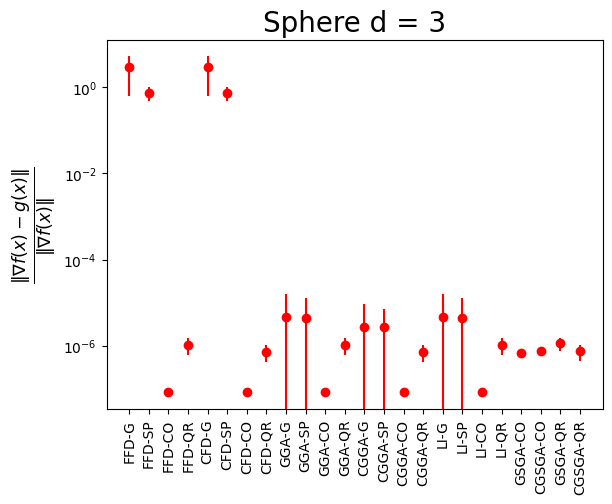

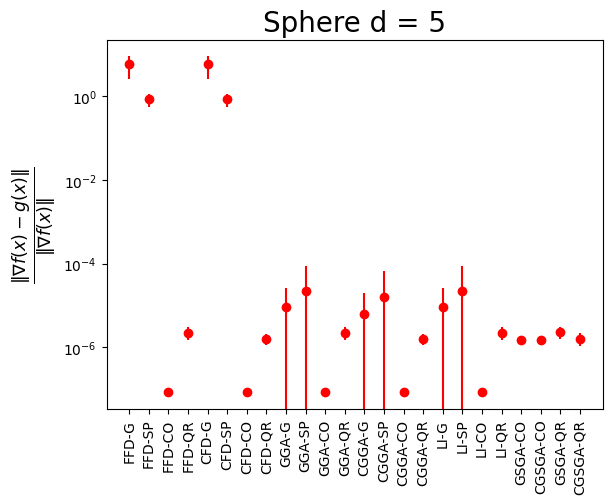

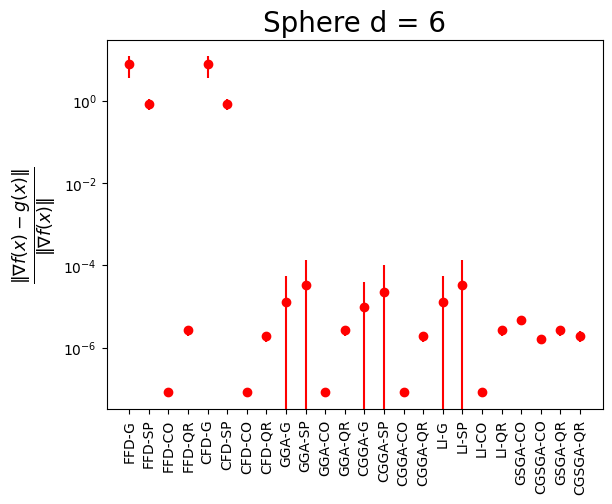

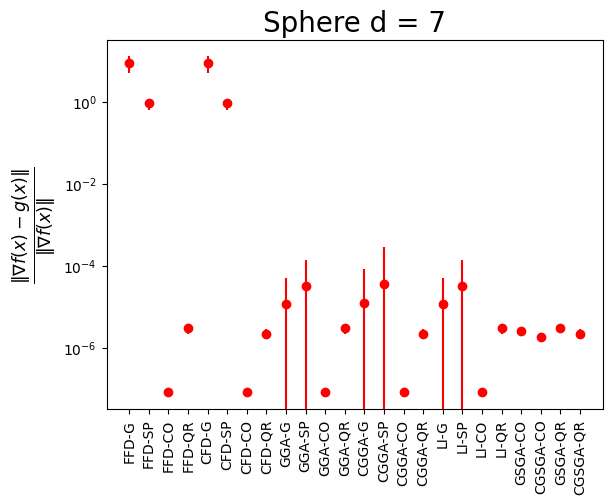

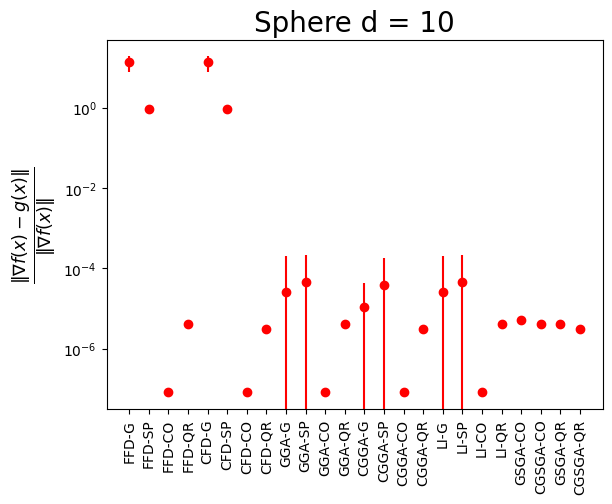

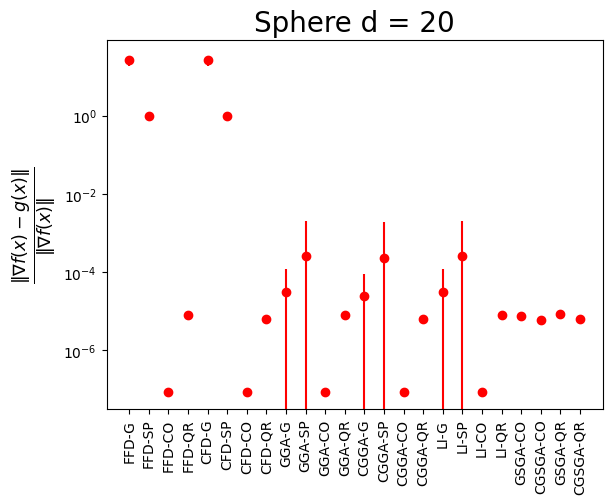

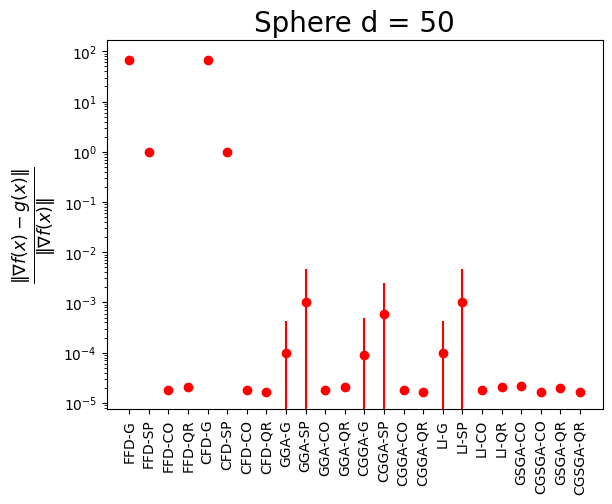

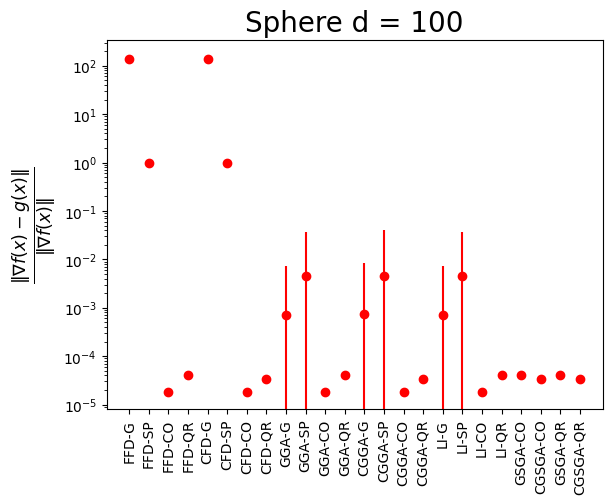

In [73]:
for d in dims:
    plot_result('Sphere d = {}'.format(d), results[d][0], 'sphere_{}_{}.pdf'.format(d, d))